# Perbandingan SARIMA vs LSTM

Langkah 6. Membandingkan prediksi SARIMA (notebook 04) dan LSTM (notebook 05) pada **data test yang sama** dengan skema yang sama (one-step-ahead), memakai RMSE, MAE, dan MAPE. Seasonal naive disertakan sebagai baseline.

Jalankan notebook 04 dan 05 terlebih dahulu; keduanya menyimpan prediksi ke `data/hasil/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import common as cm

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})

a = pd.read_csv(cm.HASIL_DIR / "pred_sarima.csv", index_col=0, parse_dates=True)
b = pd.read_csv(cm.HASIL_DIR / "pred_lstm.csv", index_col=0, parse_dates=True)
kandidat = pd.read_csv(cm.HASIL_DIR / "sarima_kandidat.csv", index_col=0)

assert a.index.equals(b.index) and np.allclose(a["aktual"], b["aktual"]), "Periode test tidak sama"
df = pd.DataFrame({"aktual": a["aktual"], "Seasonal naive": a["naive"],
                   "SARIMA": a["sarima"], "LSTM": b["lstm"]})
df.index.name = "tanggal"
print("Periode test:", df.index[0].date(), "s.d.", df.index[-1].date(), "| n =", len(df))

Periode test: 2026-01-11 s.d. 2026-10-13 | n = 276


## 1. Metrik pada data test

In [2]:
modelnya = ["Seasonal naive", "SARIMA", "LSTM"]
tabel = pd.DataFrame({m: cm.metrik(df["aktual"], df[m]) for m in modelnya}).T
tabel["Selisih RMSE vs SARIMA (%)"] = (tabel["RMSE"] / tabel.loc["SARIMA", "RMSE"] - 1) * 100
tabel.round(2)

,RMSE,MAE,MAPE (%),Selisih RMSE vs SARIMA (%)
Seasonal naive,325.20,191.65,35.88,43.77
SARIMA,226.19,133.35,27.76,0.00
LSTM,233.62,146.82,29.32,3.28


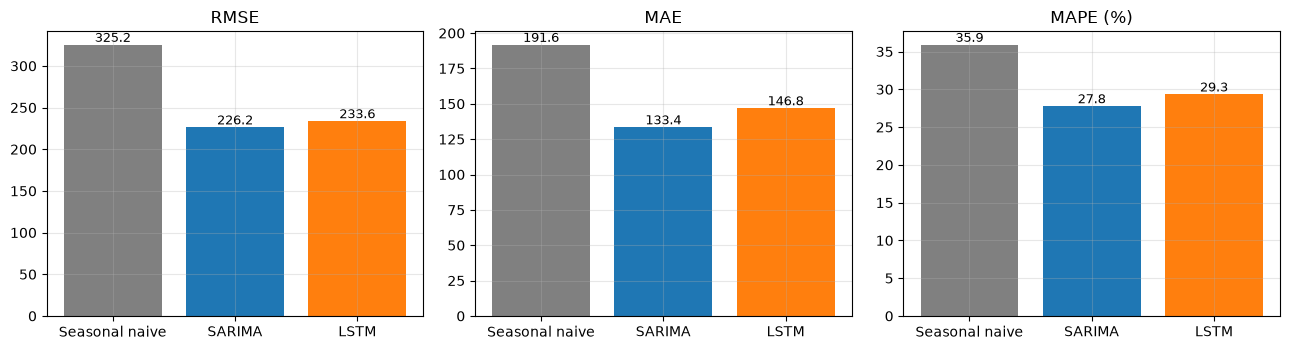

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
warna = ["gray", "tab:blue", "tab:orange"]
for ax, k in zip(axes, ["RMSE", "MAE", "MAPE (%)"]):
    ax.bar(modelnya, tabel[k], color=warna)
    for i, v in enumerate(tabel[k]):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(k)
plt.tight_layout(); plt.show()

Hasil LSTM di atas adalah ensemble 5 seed. Satu model LSTM tunggal bervariasi antar seed (lihat notebook 05), jadi perbandingan yang adil juga perlu melihat rentang seed:

In [4]:
seed_cols = [c for c in b.columns if c.startswith("lstm_seed")]
per_seed = pd.DataFrame({c: cm.metrik(b["aktual"], b[c]) for c in seed_cols}).T
pd.DataFrame({
    "SARIMA": cm.metrik(df["aktual"], df["SARIMA"]),
    "LSTM seed terbaik": per_seed.min(),
    "LSTM rata-rata seed": per_seed.mean(),
    "LSTM seed terburuk": per_seed.max(),
}).T.round(2)

,RMSE,MAE,MAPE (%)
SARIMA,226.19,133.35,27.76
LSTM seed terbaik,232.46,143.41,28.53
LSTM rata-rata seed,237.54,151.58,30.91
LSTM seed terburuk,252.50,169.25,33.71


## 2. Plot prediksi

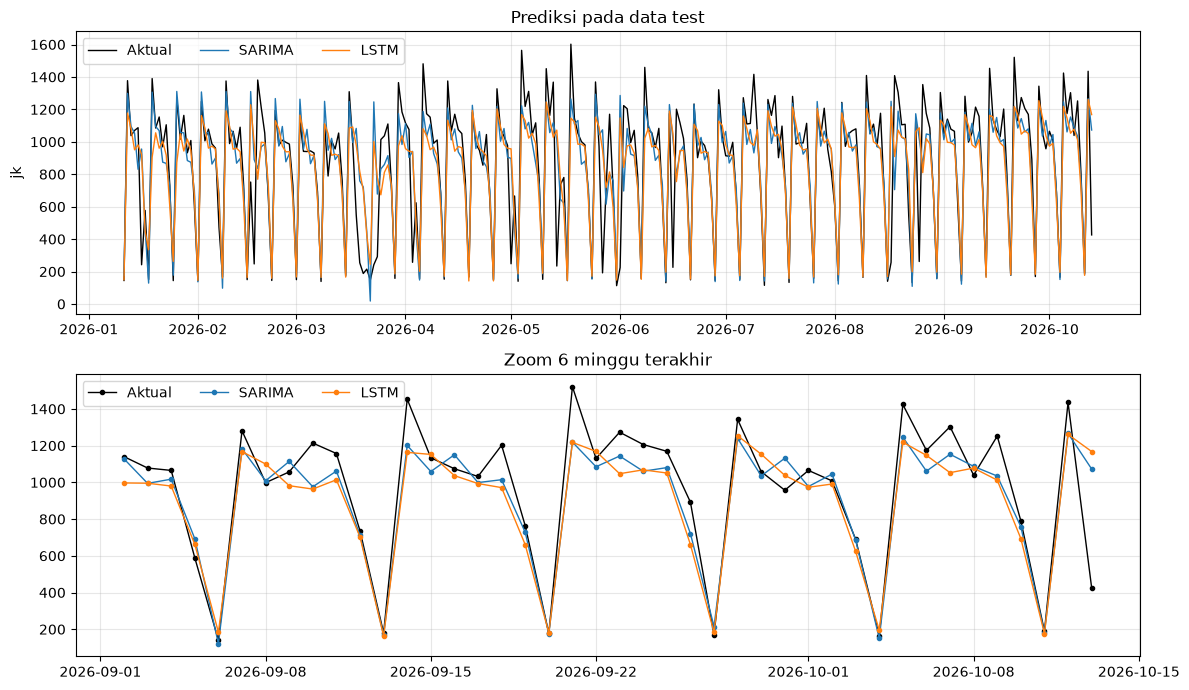

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(df["aktual"], lw=1, color="k", label="Aktual")
axes[0].plot(df["SARIMA"], lw=1, label="SARIMA")
axes[0].plot(df["LSTM"], lw=1, label="LSTM")
axes[0].set(title="Prediksi pada data test", ylabel="jk"); axes[0].legend(ncol=3)
z = df.iloc[-42:]
axes[1].plot(z["aktual"], marker="o", ms=3, lw=1, color="k", label="Aktual")
axes[1].plot(z["SARIMA"], marker="o", ms=3, lw=1, label="SARIMA")
axes[1].plot(z["LSTM"], marker="o", ms=3, lw=1, label="LSTM")
axes[1].set(title="Zoom 6 minggu terakhir"); axes[1].legend(ncol=3)
plt.tight_layout(); plt.show()

## 3. Di mana model salah?

Galat per hari dalam seminggu, dan hari-hari dengan galat terbesar. Hari dengan jumlah kunjungan sangat rendah (mis. libur) membuat MAPE membesar walaupun selisih absolutnya kecil.

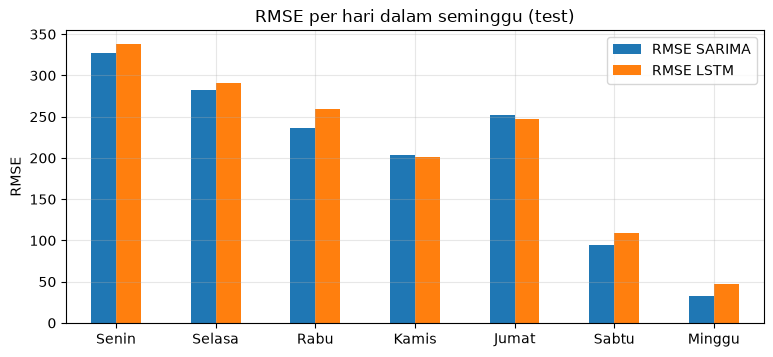

,RMSE SARIMA,RMSE LSTM
Senin,327.8,337.8
Selasa,281.9,291.0
Rabu,236.0,259.0
Kamis,203.3,200.6
Jumat,251.8,246.7
Sabtu,94.3,109.2
Minggu,32.3,46.9


In [6]:
nama_hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
err = pd.DataFrame({m: df[m] - df["aktual"] for m in ["SARIMA", "LSTM"]})
per_hari = pd.DataFrame({
    f"RMSE {m}": err[m].pow(2).groupby(df.index.dayofweek).mean().pow(.5) for m in ["SARIMA", "LSTM"]
})
per_hari.index = nama_hari
ax = per_hari.plot.bar(figsize=(9, 3.8), rot=0, color=["tab:blue", "tab:orange"])
ax.set(title="RMSE per hari dalam seminggu (test)", ylabel="RMSE")
plt.show()
per_hari.round(1)

In [7]:
besar = (df.assign(**{"galat SARIMA": err["SARIMA"], "galat LSTM": err["LSTM"]})
           .assign(hari=lambda d: [nama_hari[i] for i in d.index.dayofweek])
           .assign(maks=lambda d: d[["galat SARIMA", "galat LSTM"]].abs().max(axis=1))
           .nlargest(10, "maks")[["hari", "aktual", "SARIMA", "LSTM", "galat SARIMA", "galat LSTM"]])
besar.round(0)

,hari,aktual,SARIMA,LSTM,galat SARIMA,galat LSTM
tanggal,,,,,,
2026-06-01,Senin,225.0,1286.0,1147.0,1061.0,922.0
2026-03-23,Senin,242.0,1246.0,1001.0,1004.0,759.0
2026-08-17,Senin,257.0,1250.0,1216.0,993.0,959.0
2026-05-27,Rabu,192.0,1074.0,950.0,882.0,758.0
2026-05-14,Kamis,234.0,1014.0,1072.0,780.0,838.0
2026-06-16,Selasa,226.0,1017.0,1053.0,791.0,827.0
2026-08-25,Selasa,262.0,1019.0,1086.0,757.0,824.0
2026-02-17,Selasa,247.0,890.0,990.0,643.0,743.0
2026-10-13,Selasa,426.0,1073.0,1168.0,647.0,742.0


In [8]:
# Hari kerja (Senin-Jumat) dengan jk anjlok: kemungkinan libur/kejadian khusus yang tidak bisa diprediksi dari pola mingguan
hk = df.index.dayofweek < 5
anjlok = hk & (df["aktual"] < 0.4 * df.loc[hk, "aktual"].median())
pd.DataFrame({
    "n": [anjlok.sum(), (~anjlok).sum()],
    "MAE SARIMA": [err.loc[anjlok, "SARIMA"].abs().mean(), err.loc[~anjlok, "SARIMA"].abs().mean()],
    "MAE LSTM": [err.loc[anjlok, "LSTM"].abs().mean(), err.loc[~anjlok, "LSTM"].abs().mean()],
}, index=["Hari kerja anjlok (< 40% median hari kerja)", "Hari lainnya"]).round(1)

,n,MAE SARIMA,MAE LSTM
Hari kerja anjlok (< 40% median hari kerja),15,735.3,733.9
Hari lainnya,261,98.8,113.1


In [9]:
# Seandainya hari anjlok itu dikeluarkan, apakah urutan model berubah?
ok = ~anjlok
pd.DataFrame({m: cm.metrik(df.loc[ok, "aktual"], df.loc[ok, m]) for m in ["Seasonal naive", "SARIMA", "LSTM"]}).T.round(2)

,RMSE,MAE,MAPE (%)
Seasonal naive,256.47,152.02,17.13
SARIMA,145.13,98.76,11.91
LSTM,160.50,113.08,13.76


## 4. Apakah selisihnya signifikan? (uji Diebold-Mariano)

Selisih RMSE yang kecil belum tentu berarti satu model lebih baik. Uji Diebold-Mariano (loss kuadrat, horizon 1, varians dengan koreksi autokorelasi lag 7) menguji H0: kedua model punya akurasi prediksi yang sama.

In [10]:
def diebold_mariano(e1, e2, lag=7):
    d = np.asarray(e1) ** 2 - np.asarray(e2) ** 2
    n, dm = len(d), d.mean()
    gam = [np.mean((d[k:] - dm) * (d[:n - k] - dm)) for k in range(lag + 1)]
    var = (gam[0] + 2 * sum(gam[1:])) / n
    stat = dm / np.sqrt(var)
    return stat, 2 * (1 - stats.norm.cdf(abs(stat)))

baris = []
for m1, m2 in [("SARIMA", "LSTM"), ("Seasonal naive", "SARIMA"), ("Seasonal naive", "LSTM")]:
    e1, e2 = df[m1] - df["aktual"], df[m2] - df["aktual"]
    st, p = diebold_mariano(e1, e2)
    baris.append({"Pembanding": f"{m1} vs {m2}", "Statistik DM": st, "p-value": p,
                  "Kesimpulan (α=0,05)": "Berbeda signifikan" if p < .05 else "Tidak berbeda signifikan"})
pd.DataFrame(baris).set_index("Pembanding").round(4)

,Statistik DM,p-value,"Kesimpulan (α=0,05)"
Pembanding,,,
SARIMA vs LSTM,-1.2402,0.2149,Tidak berbeda signifikan
Seasonal naive vs SARIMA,3.0588,0.0022,Berbeda signifikan
Seasonal naive vs LSTM,2.7311,0.0063,Berbeda signifikan


## 5. Kesimpulan

**Akurasi.** Pada data test (276 hari, one-step-ahead), SARIMA(1,0,0)(0,1,1)$_7$ memberi RMSE 226,2, MAE 133,4, MAPE 27,8%. LSTM (W = 28, 32 unit, ensemble 5 seed) memberi RMSE 233,6, MAE 146,8, MAPE 29,3%. SARIMA unggul tipis pada ketiga metrik (RMSE 3,3% lebih kecil), dan keduanya jauh lebih baik daripada seasonal naive (RMSE 325,2).

**Signifikansi.** Uji Diebold-Mariano antara SARIMA dan LSTM memberi p = 0,21, jadi selisih keduanya **tidak signifikan** secara statistik. Kedua model sama-sama signifikan lebih baik daripada seasonal naive (p < 0,01). Kesimpulan yang aman: pada data ini LSTM tidak terbukti lebih baik daripada SARIMA, dan SARIMA yang jauh lebih sederhana setidaknya sebanding.

**Stabilitas.** LSTM bergantung pada seed: RMSE antar seed berkisar 232,5 sampai 252,5 (rata-rata 237,5). Ensemble 5 seed lebih baik daripada rata-rata seed tunggal, tetapi tidak ada seed LSTM yang mengalahkan SARIMA. SARIMA deterministik untuk data yang sama.

**Sumber galat terbesar.** Galat besar kedua model terkonsentrasi pada hari kerja yang jk-nya anjlok mendadak (15 hari; MAE ≈ 735 untuk kedua model, dibanding ≈ 99–113 pada hari lain). Beberapa di antaranya bertepatan dengan tanggal yang kemungkinan libur nasional (mis. 1 Juni dan 17 Agustus), tetapi ini dugaan dan belum dicek terhadap kalender libur. Pola mingguan murni tidak dapat memprediksi hari-hari ini. Menambahkan peubah libur/kalender sebagai regresor eksogen (SARIMAX dan input tambahan LSTM) adalah perbaikan yang paling menjanjikan. Jika 15 hari itu dikeluarkan, RMSE SARIMA 145,1 vs LSTM 160,5 (sifatnya deskriptif saja, karena hari dipilih berdasarkan nilai aktual).

**Keterbatasan.**
- Satu split kronologis tunggal (tidak ada validasi rolling-origin), jadi hasil bisa berbeda pada periode test lain.
- Evaluasi hanya satu langkah ke depan. Untuk peramalan beberapa hari ke depan, kedua model akan lebih buruk dan peringkatnya bisa berubah.
- LSTM univariat dengan grid hiperparameter kecil; tuning lebih luas atau tambahan fitur kalender dapat mengubah hasil.
- Koefisien MA musiman pada semua kandidat mendekati −1 dan pada empat di antaranya melewati −1 (lihat notebook 04), tanda pola mingguan sangat stabil dan differencing musiman sedikit berlebih; karena itu model invertibel (M2) yang dipilih.
- MAPE tinggi (≈ 28–29%) terutama akibat hari-hari anjlok di atas dan hari Minggu yang jk-nya kecil, bukan karena kesalahan level secara umum.

In [11]:
tabel.round(2).to_csv(cm.HASIL_DIR / "perbandingan_metrik.csv")